# Data Loading

In [1]:
import pandas as pd

data = pd.read_csv("predictions.csv", index_col = 0)
data.head()

,split_number,target_organism,curated_smiles,real_pIC50,pred_pIC50
5,0,Staphylococcus aureus,COc1cc([C@H]2Oc3ccc(C4Oc5cc(O)cc(O)c5C(=O)C4O)...,4.178294,4.824485
6,0,Staphylococcus aureus,CCOC(=O)Cn1nc(-n2cc(COc3cc(C(F)(F)F)[nH]c(=N)n...,5.134338,4.987695
26,0,Staphylococcus aureus,N=c1[nH]cc(-c2ccc(NC(=O)c3cc4ccccc4[nH]3)cc2)[...,4.045757,4.008945
65,0,Staphylococcus aureus,O=C(Nc1ccc(Sc2nc3ccccc3s2)c(Cl)c1)c1cccc(Br)c1O,6.000000,5.884717
66,0,Staphylococcus aureus,Cn1cc(-c2nn3cc(-c4ccccc4)nc3s2)c2ccccc21,4.723538,4.920264


# Prediction Analysis

## Metrics

In [2]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def analyze_results(data: pd.DataFrame):
    results = pd.DataFrame(columns=["R2", "MAE", "MSE", "RMSE"])
    for split in sorted(data.split_number.unique()):
        subdata = data[data.split_number.eq(split)]
        y_real = subdata.real_pIC50
        y_pred = subdata.pred_pIC50
        r2=r2_score(y_real, y_pred)
        mae= mean_absolute_error(y_real, y_pred)
        mse=mean_squared_error(y_real, y_pred)
        rmse=mse**0.5
        results.loc[f"Split {split}"] = [r2, mae, mse, rmse]

    results_mean, results_std = results.mean(), results.std()
    results.loc["mean"] = results_mean
    results.loc["std"] = results_std
    return results

analyze_results(data)

,R2,MAE,MSE,RMSE
Split 0,0.393550,0.381797,0.256638,0.506594
Split 1,0.377419,0.425460,0.343870,0.586404
Split 2,0.463959,0.359139,0.236901,0.486725
Split 3,0.327390,0.439191,0.380558,0.616894
Split 4,0.447159,0.376683,0.265051,0.514831
Split 5,0.384571,0.414445,0.325553,0.570573
Split 6,0.419641,0.354068,0.245038,0.495014
Split 7,0.311242,0.400064,0.297578,0.545507
Split 8,0.450137,0.386221,0.285115,0.533961
Split 9,0.473818,0.355549,0.249458,0.499458


# Graph

Text(0, 0.5, 'predicted pIC50')

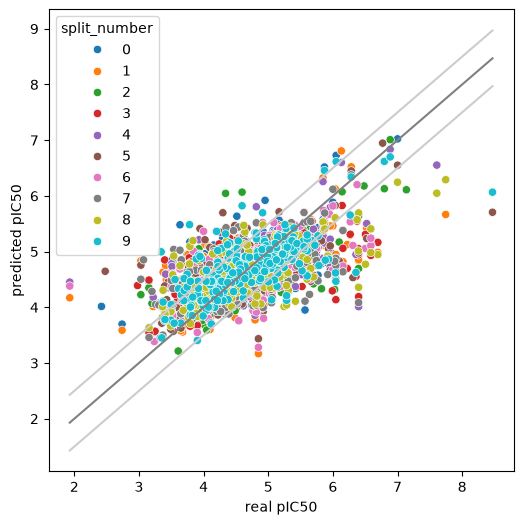

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

xmin = data.real_pIC50.min()
xmax = data.real_pIC50.max()

fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend="full")
sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None)
plt.xlabel('real pIC50')
plt.ylabel('predicted pIC50')

## RESULTS BY SPECIES

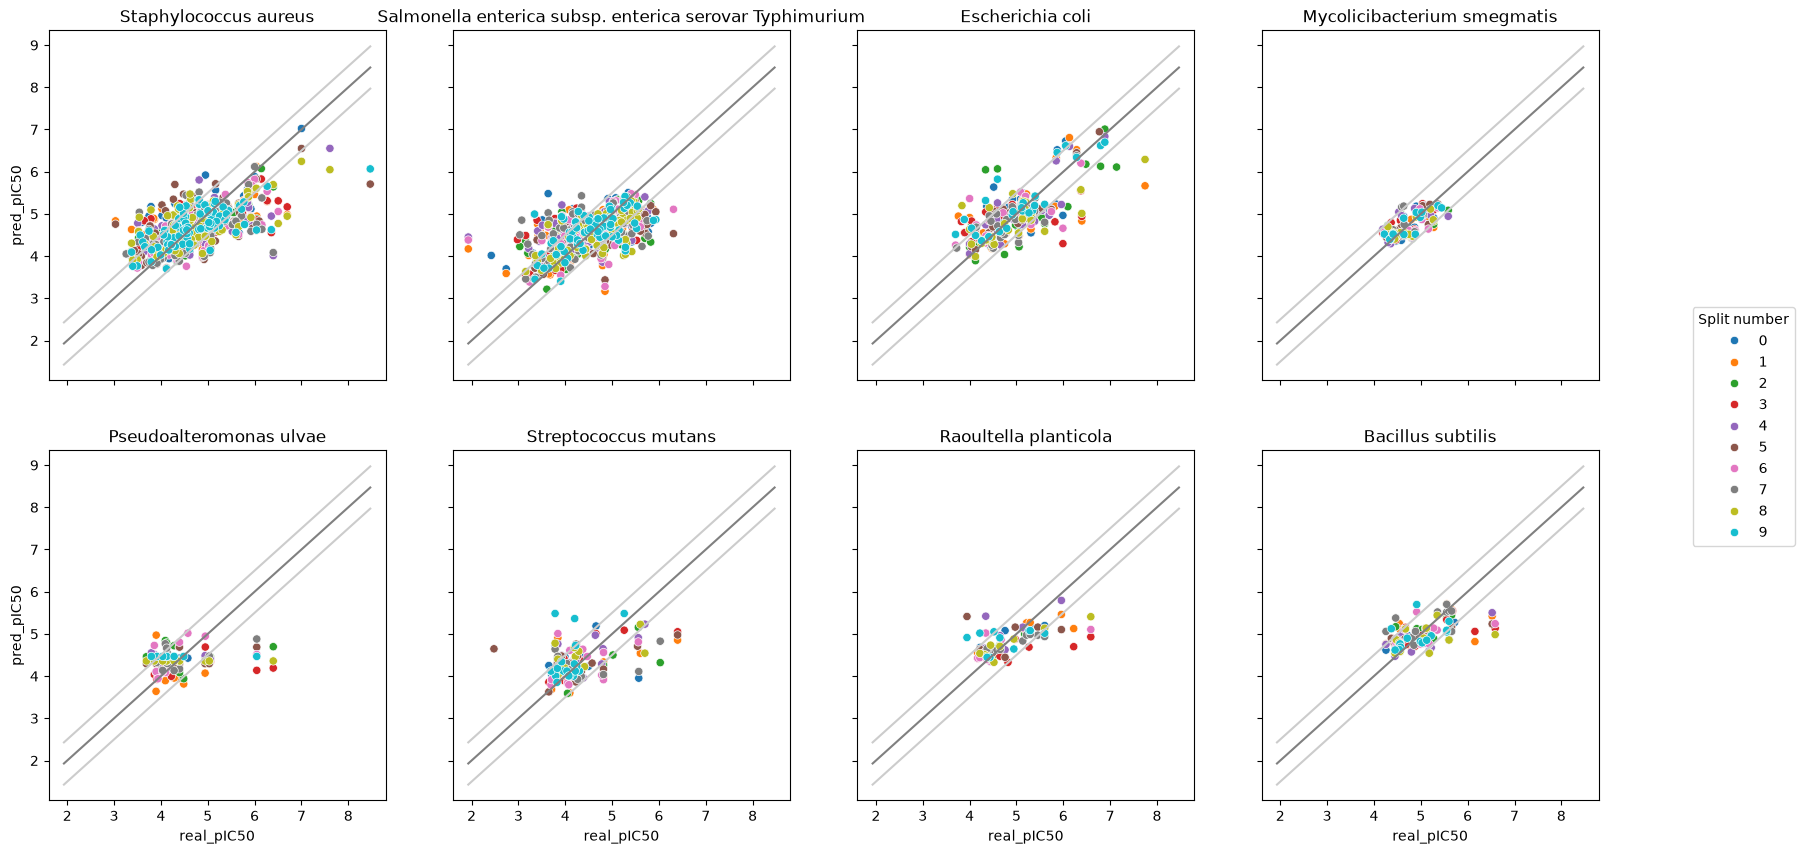

In [4]:
fig, axes = plt.subplots(2, 4, sharex="all", sharey="all", figsize = (20, 10))
for i, specie in enumerate(data.target_organism.unique()):
    ax = axes[i//4][i%4]
    subdata = data[data.target_organism.eq(specie)]
    legend = False if i else "full"
    sns.scatterplot(subdata, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend=legend, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None, ax=ax)
    ax.set_title(specie)
handles, labels = axes[0][0].get_legend_handles_labels()
axes[0][0].get_legend().remove()
fig.legend(handles, labels, loc='center right', title='Split number')

In [5]:
from collections import defaultdict

metrics = defaultdict(dict)

for specie in data.target_organism.unique():
    subdata = data[data.target_organism.eq(specie)]
    results = analyze_results(subdata)
    metrics["R2 mean"][specie] = results.loc["mean", "R2"]
    metrics["R2 std"][specie] = results.loc["std", "R2"]
    metrics["MAE mean"][specie] = results.loc["mean", "MAE"]
    metrics["MAE std"][specie] = results.loc["std", "MAE"]
    metrics["RMSE mean"][specie] = results.loc["mean", "RMSE"]
    metrics["RMSE std"][specie] = results.loc["std", "RMSE"]

metrics = pd.DataFrame(metrics)

metrics.round(3)

,R2 mean,R2 std,MAE mean,MAE std,RMSE mean,RMSE std
Staphylococcus aureus,0.426,0.089,0.401,0.049,0.541,0.070
Salmonella enterica subsp. enterica serovar Typhimurium,0.332,0.069,0.413,0.045,0.561,0.058
Escherichia coli,0.462,0.204,0.376,0.078,0.509,0.116
Mycolicibacterium smegmatis,0.370,0.322,0.207,0.035,0.252,0.044
Pseudoalteromonas ulvae,-0.130,0.441,0.467,0.093,0.624,0.158
Streptococcus mutans,-0.047,0.632,0.417,0.078,0.566,0.107
Raoultella planticola,0.389,0.283,0.309,0.111,0.442,0.163
Bacillus subtilis,0.292,0.180,0.341,0.070,0.455,0.109


In [6]:
for specie in data.target_organism.unique():
    print(specie)
    subdata = data[data.target_organism.eq(specie)]
    y_real = subdata.real_pIC50
    y_pred = subdata.pred_pIC50
    print("r2_score", r2_score(y_real, y_pred))
    print("MAE", mean_absolute_error(y_real, y_pred))
    print("MSE", mean_squared_error(y_real, y_pred))
    print("RMSE", mean_squared_error(y_real, y_pred)**.5)
    print('..............')

Staphylococcus aureus
r2_score 0.4227165668222733
MAE 0.4016544387525004
MSE 0.29786587891040484
RMSE 0.5457709033197032
..............
Salmonella enterica subsp. enterica serovar Typhimurium
r2_score 0.3355300043340702
MAE 0.41420134741404324
MSE 0.3194723006722279
RMSE 0.5652188077835237
..............
Escherichia coli
r2_score 0.4825868355497762
MAE 0.3783141949631207
MSE 0.27447231359043345
RMSE 0.5239010532442491
..............
Mycolicibacterium smegmatis
r2_score 0.4379245901958917
MAE 0.20689439218069644
MSE 0.06480373573132657
RMSE 0.2545657787907215
..............
Pseudoalteromonas ulvae
r2_score -0.030641154920767466
MAE 0.46677310424392815
MSE 0.4122743309049673
RMSE 0.6420859217464336
..............
Streptococcus mutans
r2_score 0.13954772833105378
MAE 0.41353292728163776
MSE 0.324465522314627
RMSE 0.5696187517231389
..............
Raoultella planticola
r2_score 0.3898813449471562
MAE 0.308687477554615
MSE 0.21925693751089476
RMSE 0.46824879872872577
..............
Bacillus